In [1]:
# All the libraries used in this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import norm, skew, kurtosis
from statsmodels.distributions.empirical_distribution import ECDF
from statsmodels.tsa.stattools import acf, acovf
from statsmodels.graphics.tsaplots import plot_acf

# The colours and the look of every chart of the project live in appm_style.py (one place to change them)
from appm_style import apply_style, colour, reference_line, COLOURS, OTHER_COLOURS, SERIES_COLOURS
apply_style()   # white background, hairline grid, DejaVu Sans font -> the same charts on every computer

# To create the HTML version of this notebook, run in a terminal (from the notebooks folder):
#   jupyter nbconvert --to html 02_walmart_eda.ipynb
# (the "Run notebooks" button on GitHub does it automatically)

# 02 — Walmart (WMT): exploratory analysis

**Why WMT:** the brief asks us to study the stylised facts of **one share**. We chose Walmart, a large, defensive consumer-staples company
(the reasons are in the report). This notebook is a first, mostly **visual** look at its prices and returns:

- prices and moving averages, daily / weekly / monthly log returns;
- the shape of the distribution (histograms with the normal curve, simulated normal returns, Q-Q plots, moments, quantiles, VaR);
- autocorrelation of the returns and of the squared returns.

The formal tests of the six stylised facts (Ljung-Box, Jarque-Bera, bootstrap of the skewness, ARCH-LM, GJR-GARCH) are in notebook **03**.
Data: `data/walmart_history.csv` and the log returns of notebook 01 (adjusted close prices, Yahoo Finance, 2010-2026).

In [2]:
wmt = pd.read_csv('data/walmart_history.csv', index_col=0, parse_dates=True)
# The dates in this file include a time-zone offset (-05:00 in winter, -04:00 in summer).
# Because the offset changes, recent pandas versions keep them as text, so we keep only
# the day ('YYYY-MM-DD', the first 10 characters) and turn it into real dates for the charts.
wmt.index = pd.to_datetime(wmt.index.astype(str).str[:10])
daily_returns = pd.read_csv('data/daily_log_returns.csv', index_col=0, parse_dates=True)['WMT'].dropna()
weekly_returns = pd.read_csv('data/weekly_log_returns.csv', index_col=0, parse_dates=True)['WMT'].dropna()
monthly_returns = pd.read_csv('data/monthly_log_returns.csv', index_col=0, parse_dates=True)['WMT'].dropna()
prices = pd.read_csv('data/clean_prices.csv', index_col=0, parse_dates=True)

display(daily_returns.head())


Date
2010-01-05   -0.010007
2010-01-06   -0.002238
2010-01-07    0.000560
2010-01-08   -0.005050
2010-01-11    0.016367
Name: WMT, dtype: float64

## Technical indicators: smoothing the price path

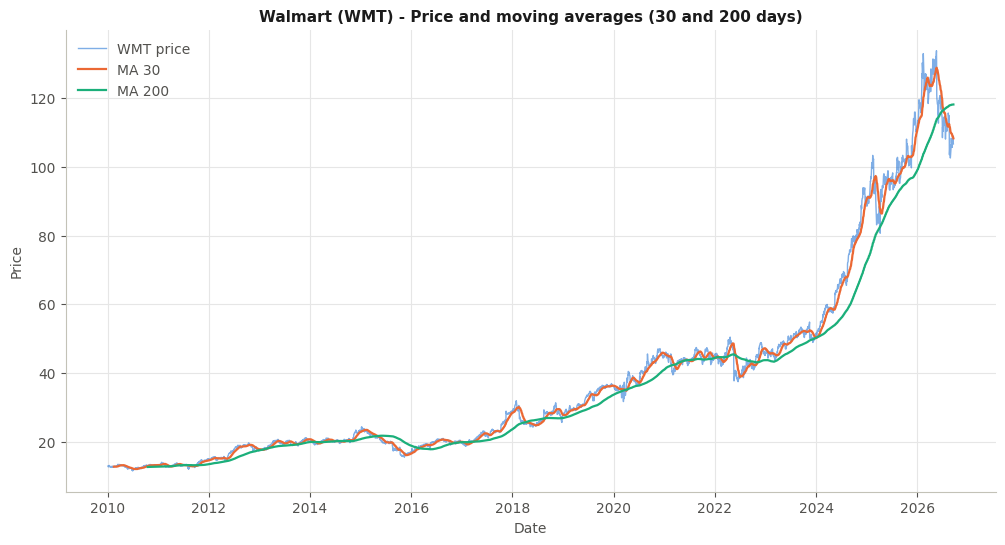

In [3]:
# Compute the simple moving averages (SMA) based on 'Adj Close'
# (the same adjusted price that is plotted below; using 'Close' would put the averages
#  above the adjusted price line in the early years, because 'Close' ignores dividends)
wmt['MA_30'] = wmt['Adj Close'].rolling(window=30).mean()
wmt['MA_200'] = wmt['Adj Close'].rolling(window=200).mean()


plt.figure(figsize=(12, 6))

# Adjusted price line (thin and a little transparent, so that the averages stand out)
plt.plot(wmt.index, wmt['Adj Close'], label='WMT price', color=COLOURS['single_series'], alpha=0.6, linewidth=1)

# Moving averages (2nd and 3rd colours of the series list)
plt.plot(wmt.index, wmt['MA_30'], label='MA 30', color=SERIES_COLOURS[1], linewidth=1.6)
plt.plot(wmt.index, wmt['MA_200'], label='MA 200', color=SERIES_COLOURS[2], linewidth=1.6)

# Chart settings
plt.title('Walmart (WMT) - Price and moving averages (30 and 200 days)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend(loc='upper left')

# Save the chart in the figures folder
plt.savefig('../figures/wmt_moving_averages.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** the adjusted price of WMT rose strongly over 2010-2026 (it was multiplied by about 8). The 30-day average follows the price closely; the 200-day average smooths the long-term trend. Moving averages are only descriptive here (no trading rule is tested).

##  Walmart log returns

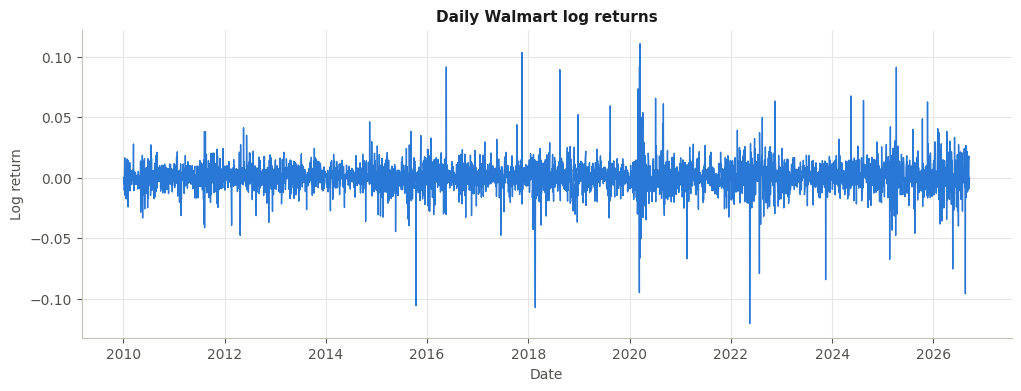

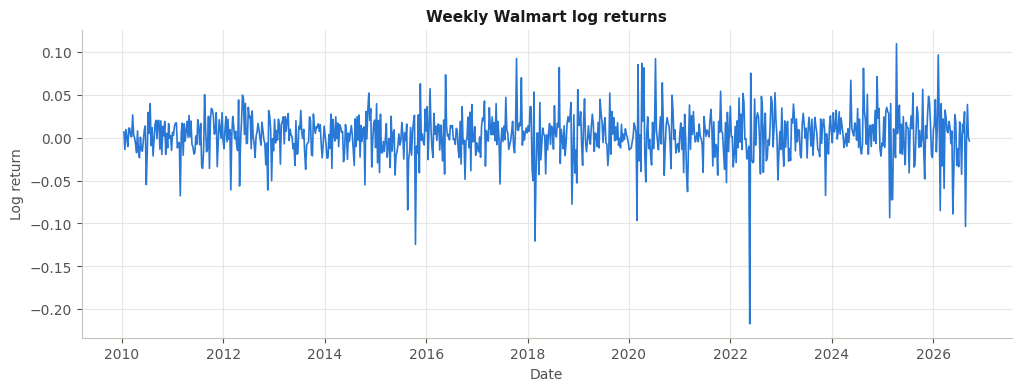

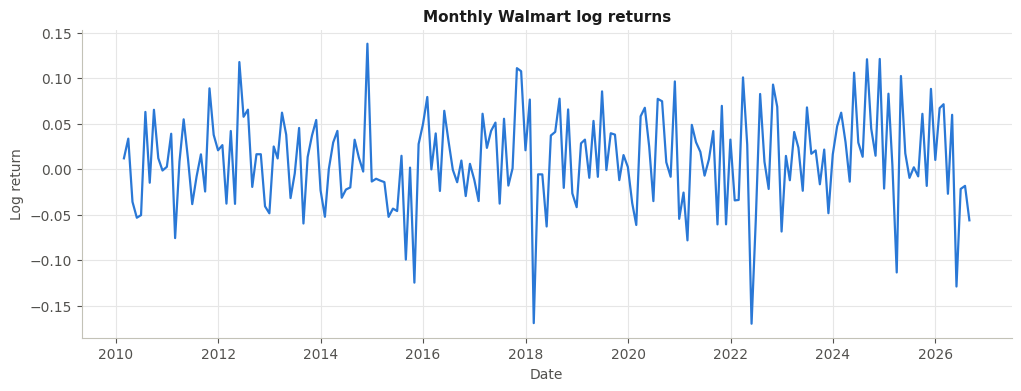

In [4]:
# The three charts show the same stock (WMT), so they all use the single-series colour

# --- Daily
plt.figure(figsize=(12, 4))
plt.plot(daily_returns.index, daily_returns, color=colour('WMT'), linewidth=1)
plt.title('Daily Walmart log returns')
plt.xlabel('Date')
plt.ylabel('Log return')
plt.savefig('../figures/day_log_returns.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Weekly ---
plt.figure(figsize=(12, 4))
plt.plot(weekly_returns.index, weekly_returns, color=colour('WMT'), linewidth=1.2)
plt.title('Weekly Walmart log returns')
plt.xlabel('Date')
plt.ylabel('Log return')
plt.savefig('../figures/week_log_returns.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Monthly ---
plt.figure(figsize=(12, 4))
plt.plot(monthly_returns.index, monthly_returns, color=colour('WMT'), linewidth=1.6)
plt.title('Monthly Walmart log returns')
plt.xlabel('Date')
plt.ylabel('Log return')
plt.savefig('../figures/month_log_returns.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** the log returns move around zero, mostly within about ±3% a day, with a few very large moves (−12.1% and +11.1%) — usually on quarterly-results days and in March 2020. Calm and turbulent periods alternate (volatility clustering, tested in notebook 03). Aggregating to weeks and months makes the series smoother.

## Normalised price

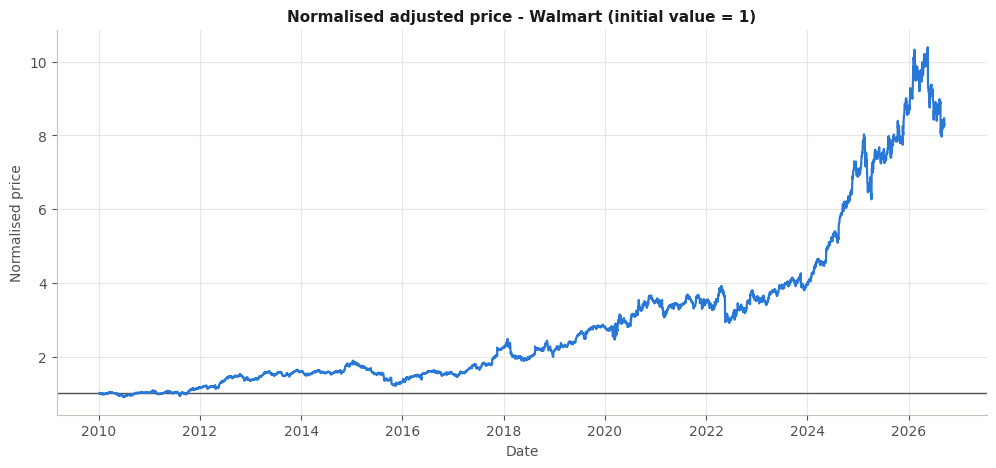

In [5]:
wmt_price = prices['WMT']

# Normalise the price by dividing it by the value on the first day
wmt_normalised = wmt_price / wmt_price.iloc[0]


plt.figure(figsize=(12, 5))
plt.plot(wmt_normalised.index, wmt_normalised, color=colour('WMT'), linewidth=1.6, label='WMT')

# Settings
plt.title('Normalised adjusted price - Walmart (initial value = 1)')
plt.xlabel('Date')
plt.ylabel('Normalised price')
reference_line(plt.gca(), y=1.0)  # Reference line at the starting value (only one series, so no legend is needed)

plt.savefig('../figures/normalized_price_history.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** 1 USD invested in WMT at the start of 2010 (dividends reinvested, because the price is adjusted) was worth about 8 USD in September 2026, most of the gain coming after 2018.

## Annualised realised performance

In [6]:
# Walmart's adjusted price (cell above) and compute the daily simple returns
simple_returns = wmt_price.pct_change().dropna()

# Annualisation parameters
scale = 252  # Trading days in a year
rf = 0.0     # (zero risk-free rate)

# Annualised metrics
# Annualised compound return (CAGR)
annualised_return = (1 + simple_returns).prod() ** (scale / len(simple_returns)) - 1

# Annualised standard deviation (volatility)
annualised_volatility = simple_returns.std() * np.sqrt(scale)

# Return / volatility ratio (CAGR divided by volatility, with a zero risk-free rate).
# Note: it is NOT the Sharpe ratio of notebook 04, which uses the daily excess return over the DGS3 rate.
return_to_volatility = (annualised_return - rf) / annualised_volatility

# table
perf_table = pd.DataFrame({
    'Annualised return (CAGR)': [annualised_return],
    'Annualised volatility': [annualised_volatility],
    'Return / volatility (rf = 0)': [return_to_volatility]
}, index=['WMT'])

print("Annualised performance from simple returns; zero risk-free rate")
display(perf_table.round(4))

Annualised performance from simple returns; zero risk-free rate


,Annualised return (CAGR),Annualised volatility,Return / volatility (rf = 0)
WMT,0.1352,0.1999,0.6765


**Reading:** compound annual return ≈ 13.5% with annual volatility ≈ 20%. The return / volatility ratio (≈ 0.68) uses a zero risk-free rate; the Sharpe ratios of the backtest (notebook 04) subtract the daily 3-year Treasury rate and use the average daily excess return, so they are not directly comparable.

## Distribution of the log returns at the three frequencies

Histograms of the daily, weekly and monthly log returns with the normal curve of the same mean and standard deviation.

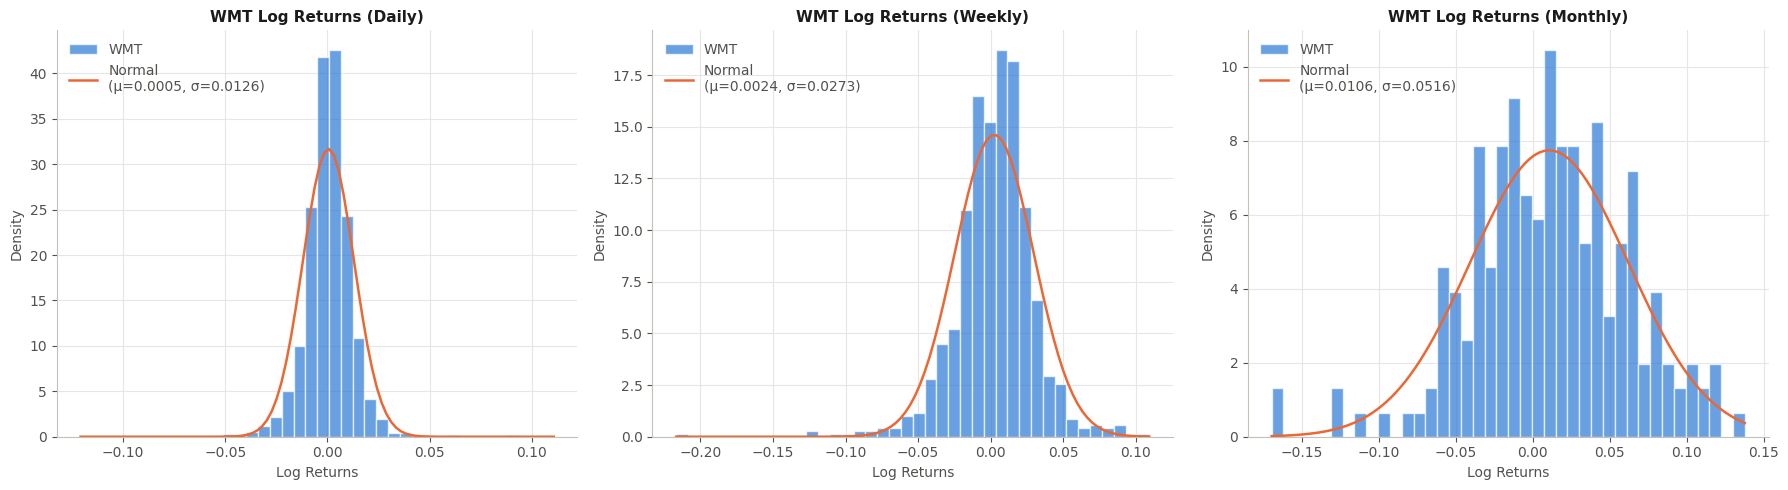

In [7]:
# Set up the figure with 3 subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

frequencies = [('Daily', daily_returns, axes[0]),
               ('Weekly', weekly_returns, axes[1]),
               ('Monthly', monthly_returns, axes[2])]

for title, data, ax in frequencies:
    # Histogram (WMT colour, white edges between the bars)
    ax.hist(data, bins=40, density=True, color=colour('WMT'), edgecolor=COLOURS['background'], alpha=0.7,
            label='WMT')

    # Fit the normal distribution (same mean and standard deviation as the data)
    mu, std = norm.fit(data)
    x = np.linspace(data.min(), data.max(), 100)
    p = norm.pdf(x, mu, std)

    # Draw the normal curve
    ax.plot(x, p, color=colour('Normal'), linewidth=1.8, label=f'Normal\n(μ={mu:.4f}, σ={std:.4f})')

    # Visual details
    ax.set_title(f'WMT Log Returns ({title})')
    ax.set_xlabel('Log Returns')
    ax.set_ylabel('Density')
    ax.legend(loc='upper left')   # the upper-left corner is empty in the three panels (only the left tail is there)

plt.tight_layout()
plt.savefig('../figures/wmt_log_returns_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** at the daily frequency the histogram is much more peaked than the normal curve and has longer tails (fat tails); the weekly histogram is still peaked; the monthly one is much closer to the normal curve. Non-normality fades as returns are aggregated (tested in notebook 03, fact 2).

## WMT returns vs simulated normal returns

We simulate a series of normal returns (Gaussian white noise) with the **same mean, volatility and length** as WMT and draw both with the same scales.

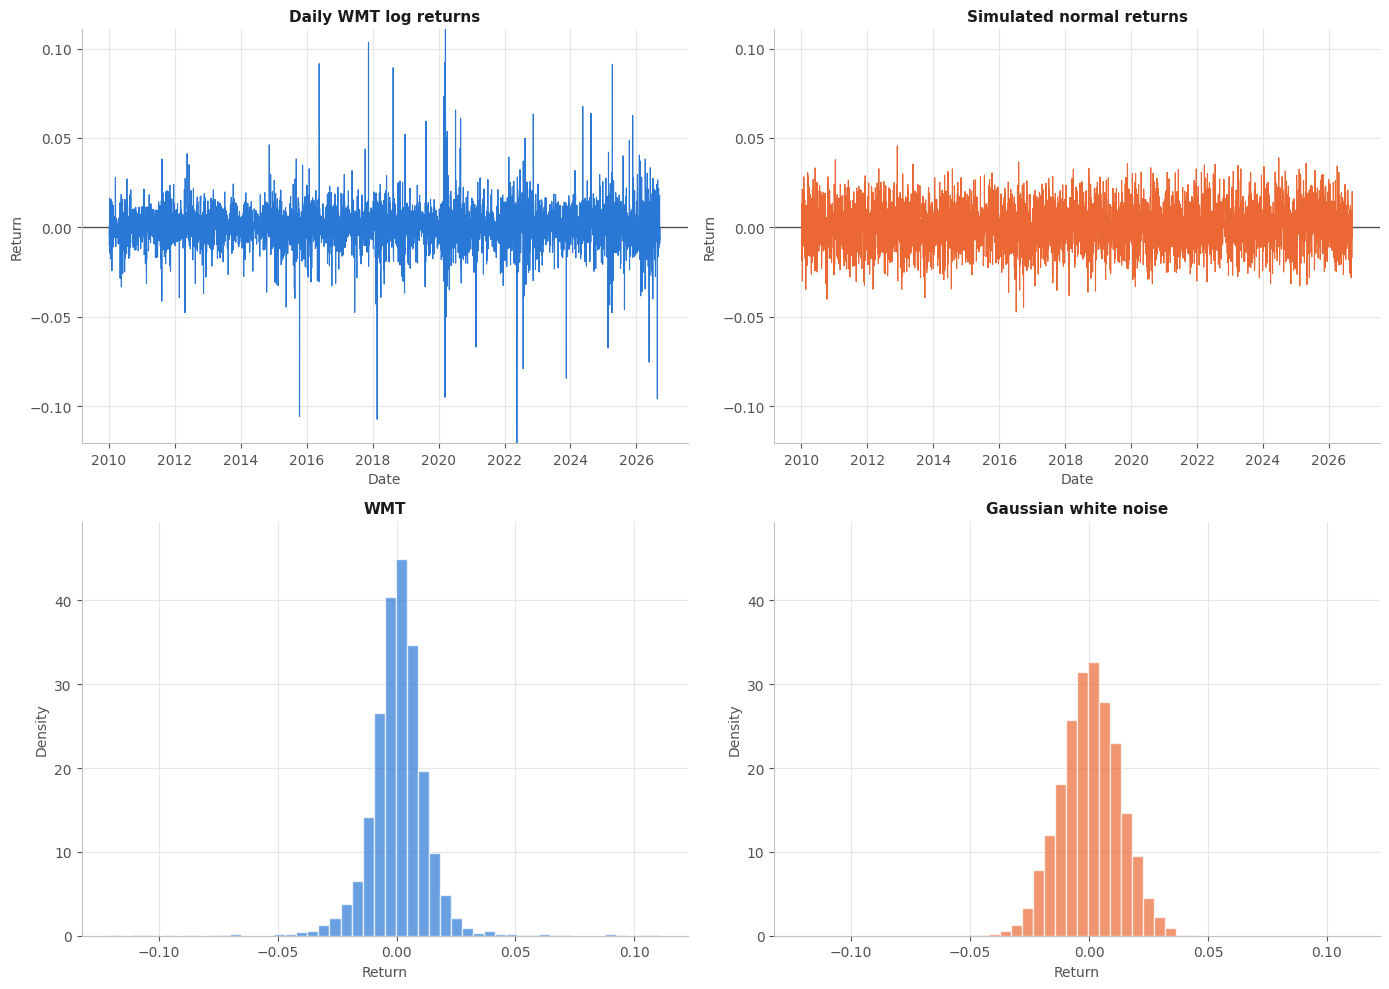

In [8]:
# Fixed seed -> the simulated series is always the same
np.random.seed(123)

# Reuse the daily returns we already have
wmt_ret = daily_returns
# Generate Gaussian white noise with the same mean, standard deviation and length as WMT
mu = wmt_ret.mean()
std = wmt_ret.std()
gwn_daily = pd.Series(np.random.normal(loc=mu, scale=std, size=len(wmt_ret)), index=wmt_ret.index)

# Set common axis limits (so that the two series can be compared directly)
y_limits = (min(wmt_ret.min(), gwn_daily.min()), max(wmt_ret.max(), gwn_daily.max()))

# -------------------------------------------------------------------
# Create a 2x2 grid of charts
# WMT is drawn in the WMT colour and the simulated normal returns in the 'Normal' colour
# -------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Chart 1: actual time series (WMT) ---
axes[0, 0].plot(wmt_ret.index, wmt_ret, color=colour('WMT'), linewidth=0.8)
reference_line(axes[0, 0], y=0)
axes[0, 0].set_ylim(y_limits)
axes[0, 0].set_title('Daily WMT log returns')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Return')

# --- Chart 2: simulated time series (Gaussian White Noise) ---
axes[0, 1].plot(gwn_daily.index, gwn_daily, color=colour('Normal'), linewidth=0.8)
reference_line(axes[0, 1], y=0)
axes[0, 1].set_ylim(y_limits)
axes[0, 1].set_title('Simulated normal returns')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Return')

# --- Create the same bins for both histograms ---
bins = np.linspace(y_limits[0], y_limits[1], 51)

# --- Chart 3: actual histogram (WMT) ---
count_wmt, _, _ = axes[1, 0].hist(wmt_ret, bins=bins, density=True, color=colour('WMT'),
                                  edgecolor=COLOURS['background'], alpha=0.7)
axes[1, 0].set_title('WMT')
axes[1, 0].set_xlabel('Return')
axes[1, 0].set_ylabel('Density')

# --- Chart 4: simulated histogram (Gaussian White Noise) ---
count_gwn, _, _ = axes[1, 1].hist(gwn_daily, bins=bins, density=True, color=colour('Normal'),
                                  edgecolor=COLOURS['background'], alpha=0.7)
axes[1, 1].set_title('Gaussian white noise')
axes[1, 1].set_xlabel('Return')
axes[1, 1].set_ylabel('Density')

# Use the same Y-axis scale in both histograms for a visual comparison
max_y_hist = max(count_wmt.max(), count_gwn.max()) * 1.1
axes[1, 0].set_ylim(0, max_y_hist)
axes[1, 1].set_ylim(0, max_y_hist)

plt.tight_layout()
plt.savefig('../figures/wmt_log_returns_vs_normal.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** the simulated normal returns (same mean and volatility) never show moves like the −12% and +11% days of WMT, and their histogram is lower in the centre: the real returns have **fat tails** and a **sharper peak** than a normal distribution with the same volatility.

## Fitted normal density on the actual histogram

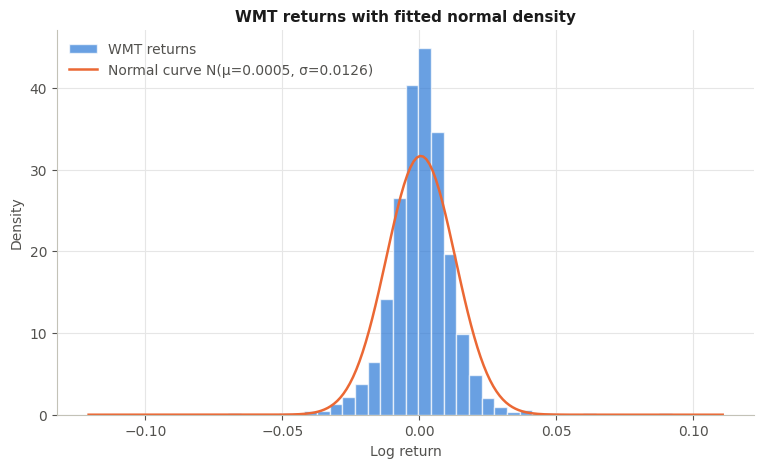

In [9]:
#Create the histogram
plt.figure(figsize=(9, 5))

count, bins, _ = plt.hist(
    wmt_ret,
    bins=50,
    density=True,
    color=colour('WMT'),
    edgecolor=COLOURS['background'],
    alpha=0.7,
    label='WMT returns'
)

# Overlay the curve of the fitted normal distribution
mu = wmt_ret.mean()
std = wmt_ret.std()

x = np.linspace(wmt_ret.min(), wmt_ret.max(), 200)
p = norm.pdf(x, mu, std)  # pdf = probability density function of the normal distribution

plt.plot(x, p, color=colour('Normal'), linewidth=1.8, label=f'Normal curve N(μ={mu:.4f}, σ={std:.4f})')

# Visual settings
plt.title("WMT returns with fitted normal density")
plt.xlabel("Log return")
plt.ylabel("Density")
plt.legend(loc='upper left')   # empty corner (only the left tail is there)

plt.savefig('../figures/wmt_distribution_with_normal.png', dpi=150, bbox_inches='tight')
plt.show()

**Reading:** the bars in the centre rise above the normal curve, the shoulders fall below it, and the extreme bars lie outside it: the classic shape of a fat-tailed (leptokurtic) distribution.

## Empirical cumulative distribution function

Empirical probability of a daily drop greater than 5%:


,Threshold,Empirical_probability
0,-0.051293,0.002856


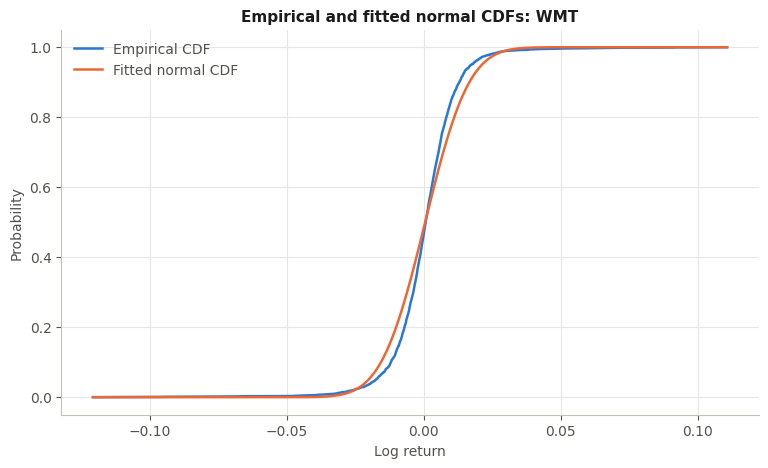

In [10]:
# the threshold (5% drop -> log(0.95)) and compute the empirical probability
threshold = np.log(0.95)
f_hat = (wmt_ret <= threshold).mean()

# Create and display the table
prob_table = pd.DataFrame({
    'Threshold': [threshold],
    'Empirical_probability': [f_hat]
})

print("Empirical probability of a daily drop greater than 5%:")
display(prob_table.round(6))

# Compute the ECDF (empirical cumulative distribution function)
# We give ECDF a copy (.copy()) because ECDF sorts the data it receives. wmt_ret is just
# another name for daily_returns, so with some library versions (pandas 2.2 + numpy 2)
# daily_returns itself would end up sorted and the ACF results further down would be wrong.
ecdf = ECDF(wmt_ret.copy())

# Draw the CDF chart (empirical vs theoretical normal)
plt.figure(figsize=(9, 5))

# Actual ECDF of the data (WMT colour)
x_ecdf = np.sort(wmt_ret)
plt.plot(x_ecdf, ecdf(x_ecdf), color=colour('WMT'), linewidth=1.8, label='Empirical CDF')

# Theoretical normal CDF ('Normal' colour)
mu, std = wmt_ret.mean(), wmt_ret.std()
x = np.linspace(wmt_ret.min(), wmt_ret.max(), 300)
plt.plot(x, norm.cdf(x, mu, std), color=colour('Normal'), linewidth=1.8, label='Fitted normal CDF')


plt.title("Empirical and fitted normal CDFs: WMT")
plt.xlabel("Log return")
plt.ylabel("Probability")
plt.legend(loc='upper left')

plt.show()

**Reading:** a daily fall of more than 5% happened on about 0.29% of the days (≈ 12 days in 16 years). The empirical CDF lies above the normal CDF in the far left tail: large falls are more frequent than a normal distribution would predict.

## Empirical quantiles and percentiles

In [11]:
# 1. Define the vector of probabilities
probs = [0.01, 0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975, 0.99]

# 2. Compute the WMT quantiles using interpolation='linear' (the usual definition of a quantile)
ret_quant_wmt = daily_returns.quantile(probs, interpolation='linear')

# 3. Format as a DataFrame with a column name
quantile_table = pd.DataFrame(ret_quant_wmt)
quantile_table.columns = ['WMT']
quantile_table.index.name = 'quantile'

# Display with 5 decimal places
print("Daily log-return quantiles")
display(quantile_table.round(5))


# Use our Walmart daily returns variable
wmt_summary = daily_returns.describe()

# Arrange as a summary table (minimum, quartiles, median, mean, maximum)
summary_r = pd.Series({
    'Min.': wmt_summary['min'],
    '1st Qu.': wmt_summary['25%'],
    'Median': wmt_summary['50%'],
    'Mean': wmt_summary['mean'],
    '3rd Qu.': wmt_summary['75%'],
    'Max.': wmt_summary['max']
}, name='WMT')

# Display formatted as a table
display(pd.DataFrame(summary_r).round(6))

Daily log-return quantiles


,WMT
quantile,
0.010,-0.03254
0.025,-0.02376
0.050,-0.01746
0.250,-0.00535
0.500,0.00069
0.750,0.00655
0.950,0.01741
0.975,0.02240
0.990,0.03170


,WMT
Min.,-0.120765
1st Qu.,-0.005347
Median,0.000686
Mean,0.000503
3rd Qu.,0.006549
Max.,0.110723


In [12]:
# 1. Define the initial value of the position (initial investment)
V0 = 100000  # Example: 100,000 € / $

# 2. Define the confidence levels and the corresponding left-tail probabilities
confidence_levels = ['99% confidence', '97.5% confidence', '95% confidence']
probs = [0.01, 0.025, 0.05]

# -------------------------------------------------------------------
# Method 1: VaR transformed from the log returns
# -------------------------------------------------------------------
# Reuses 'daily_returns' (which is already the WMT series)
q_log = daily_returns.quantile(probs, interpolation='linear')
var_log_transformed = -V0 * (np.exp(q_log) - 1)

df_var_log = pd.DataFrame({'WMT': var_log_transformed.values}, index=confidence_levels)

print("One-day VaR: transformed log quantiles")
display(df_var_log.round(1))

# -------------------------------------------------------------------
# Method 2: VaR directly from the simple returns
# -------------------------------------------------------------------
# Get the simple returns (pct_change) from the WMT price history
wmt_prices = wmt['Adj Close']
simple_returns = wmt_prices.pct_change().dropna()

q_simple = simple_returns.quantile(probs, interpolation='linear')
var_direct = -V0 * q_simple

df_var_direct = pd.DataFrame({'WMT': var_direct.values}, index=confidence_levels)

print("One-day VaR: direct simple-return quantiles")
display(df_var_direct.round(1))

One-day VaR: transformed log quantiles


,WMT
99% confidence,3201.6
97.5% confidence,2347.6
95% confidence,1730.5


One-day VaR: direct simple-return quantiles


,WMT
99% confidence,3201.6
97.5% confidence,2347.6
95% confidence,1730.5


**Reading:** with 100,000 invested, the one-day historical VaR is ≈ 3,200 at 99%, ≈ 2,350 at 97.5% and ≈ 1,730 at 95%. Both methods give the same values (the log and simple quantiles are converted exactly). Under a normal distribution with the same mean and volatility the 99% VaR would be smaller (≈ 2,850): the normal model understates tail risk.

## Quantile-quantile plots with Standardisation

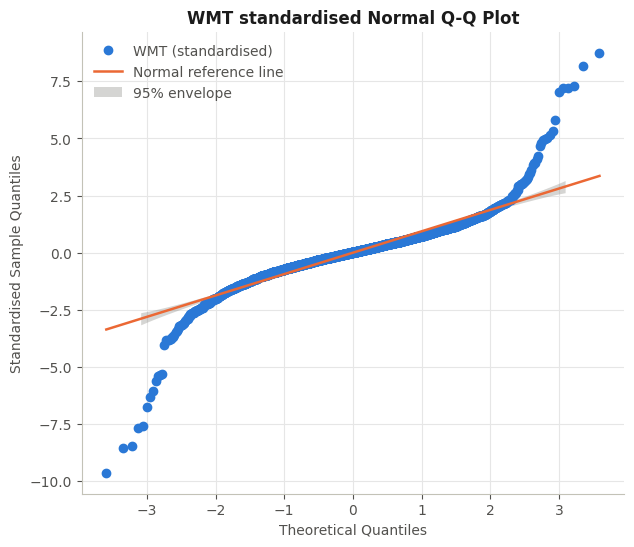

In [13]:
def style_qq_plot(ax, line_colour, points_label, line_label):
    """Gives a scipy Q-Q plot (stats.probplot) the project colours: WMT dots and a reference line in line_colour."""
    points = ax.get_lines()[0]                   # the first line drawn by probplot = the data points
    points.set_color(colour('WMT'))
    points.set_markersize(6)                     # no white edge here: about 4,200 dots overlap along the line,
                                                 # and white edges would make the centre look washed out
    points.set_label(points_label)
    line = ax.get_lines()[1]                     # the second line = the theoretical (reference) line
    line.set_color(line_colour)
    line.set_linewidth(1.8)
    line.set_label(line_label)


# 1. Get the Walmart returns
wmt_ret = daily_returns.dropna()

# 2. Standardise the series (Z-score: mean 0, standard deviation 1)
wmt_std = (wmt_ret - wmt_ret.mean()) / wmt_ret.std()

# 3. Create the figure for the standardised QQ-plot
fig, ax = plt.subplots(figsize=(7, 6))

# QQ-plot with the standardised data
(osm, osr), (slope, intercept, r) = stats.probplot(wmt_std, dist="norm", plot=ax)

# Visual customisation (WMT dots, normal reference line)
style_qq_plot(ax, colour('Normal'), 'WMT (standardised)', 'Normal reference line')

# 95% confidence envelope
n = len(wmt_std)
grid = np.linspace(0.001, 0.999, n)
theoretical_quantiles = stats.norm.ppf(grid)
se = (slope / stats.norm.pdf(theoretical_quantiles)) * np.sqrt(grid * (1 - grid) / n)

upper_env = (theoretical_quantiles * slope + intercept) + 1.96 * se
lower_env = (theoretical_quantiles * slope + intercept) - 1.96 * se

# The envelope is drawn as a light grey band (behind the dots)
ax.fill_between(theoretical_quantiles, lower_env, upper_env, color=COLOURS['muted'], alpha=0.35,
                linewidth=0, zorder=1, label='95% envelope')

# Title and axes
ax.set_title("WMT standardised Normal Q-Q Plot", fontsize=12)
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Standardised Sample Quantiles")
ax.legend(loc='upper left')

plt.show()

**Reading:** the points follow the reference line in the centre but bend away from it at both ends (an S shape): the extreme returns are far more extreme than the normal distribution allows → fat tails. The grey band is the pointwise 95% range expected under normality.

## Student-t reference: an alternative tail shape

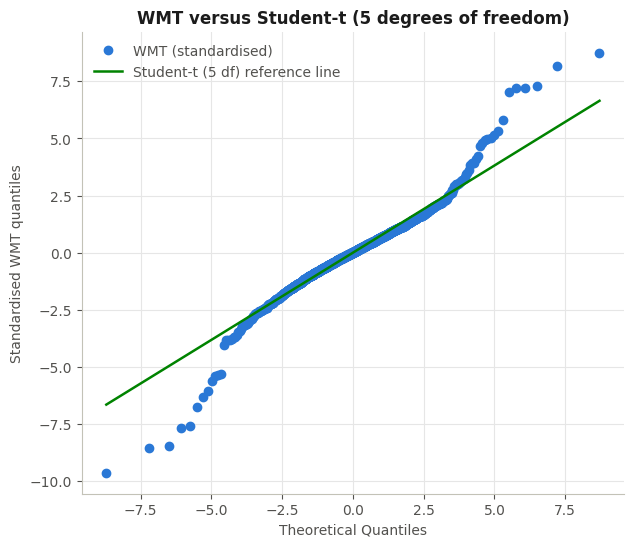

In [14]:
# 1. Use the Walmart daily returns and standardise them
wmt_ret = daily_returns.dropna()
wmt_std = (wmt_ret - wmt_ret.mean()) / wmt_ret.std()

# 2. Set the degrees of freedom (df = 5)
df_student = 5

# 3. Create the QQ-plot against the Student-t distribution
fig, ax = plt.subplots(figsize=(7, 6))

# stats.probplot using the 't' distribution with sparams=(df_student,)
(osm, osr), (slope, intercept, r) = stats.probplot(
    wmt_std,
    dist="t",
    sparams=(df_student,),
    plot=ax
)

# 4. Colours: WMT dots, Student-t reference line
#    (style_qq_plot is defined in the normal Q-Q plot cell above)
style_qq_plot(ax, colour('Student-t'), 'WMT (standardised)', f'Student-t ({df_student} df) reference line')

# Titles and axes
ax.set_title(f"WMT versus Student-t ({df_student} degrees of freedom)", fontsize=12)
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Standardised WMT quantiles")
ax.legend(loc='upper left')

plt.show()

**Reading:** against a Student-t distribution (5 degrees of freedom) the points stay much closer to the line, including most of the tails: a fat-tailed distribution describes WMT returns better than the normal.

## Shape characteristics and boxplots

In [15]:
# 1. Use our Walmart daily returns variable
wmt_ret = daily_returns.dropna()

# 2. Compute the statistical moments
mean_val = wmt_ret.mean()
sd_val = wmt_ret.std()  # Sample standard deviation (ddof=1 by default in pandas)
skew_val = skew(wmt_ret)  # Skewness
kurt_val = kurtosis(wmt_ret, fisher=False)  # Raw kurtosis (Pearson)
ex_kurt_val = kurtosis(wmt_ret, fisher=True)  # Excess kurtosis (Kurtosis - 3)

# 3. Arrange in a table with 5 decimal places
moments_wmt = pd.DataFrame({
    'Mean': [mean_val],
    'SD': [sd_val],
    'Skewness': [skew_val],
    'Kurtosis': [kurt_val],
    'Excess.Kurtosis': [ex_kurt_val]
}, index=['WMT']).T

print("Distributional moments of daily log returns")
display(moments_wmt.round(5))

Distributional moments of daily log returns


,WMT
Mean,0.00050
SD,0.01259
Skewness,-0.25459
Kurtosis,17.32108
Excess.Kurtosis,14.32108


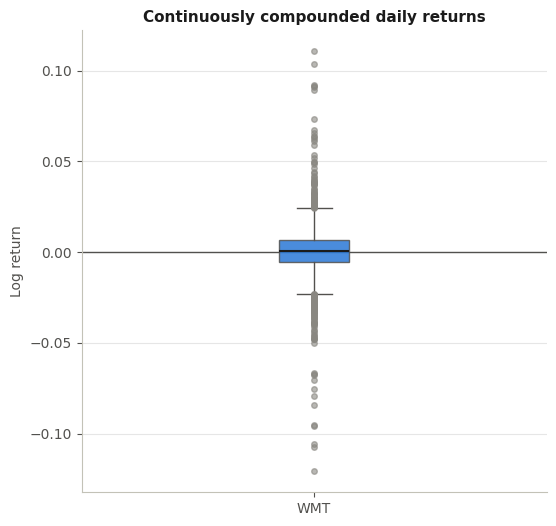

In [16]:
# 1. Use the Walmart daily returns
wmt_ret = daily_returns.dropna()

# 2. Create the boxplot figure
plt.figure(figsize=(6, 6))

# Boxplot filled with the WMT colour; grey edges and whiskers, dark median line, small grey dots for the outliers
box = plt.boxplot(
    wmt_ret,
    patch_artist=True,
    tick_labels=['WMT'],  # this argument was called 'labels' before matplotlib 3.9
    boxprops=dict(facecolor=colour('WMT'), edgecolor=COLOURS['text_secondary'], alpha=0.85),
    whiskerprops=dict(color=COLOURS['text_secondary']),
    capprops=dict(color=COLOURS['text_secondary']),
    medianprops=dict(color=COLOURS['text'], linewidth=1.5),
    flierprops=dict(marker='o', markerfacecolor=COLOURS['muted'], markeredgecolor=COLOURS['muted'],
                    markersize=4, alpha=0.6)
)

# 3. Add a horizontal reference line at 0
reference_line(plt.gca(), y=0)

# Visual settings
plt.title("Continuously compounded daily returns")
plt.ylabel("Log return")
plt.gca().xaxis.grid(False)   # only horizontal gridlines (a vertical one would cross the box)

plt.show()

**Reading:** the box (the middle 50% of the days) is narrow, but there are many outliers on both sides — another view of the fat tails. Mean ≈ 0.05% a day, skewness ≈ −0.25 (slightly negative), excess kurtosis ≈ 14.3 (0 for a normal distribution).

## Autocovariance and autocorrelation

In [17]:
# 1. Use the Walmart daily returns
wmt_ret = daily_returns.dropna()

# 2. Set the maximum number of lags (50)
lag_max = 50

# 3. Autocorrelation
acf_values = acf(wmt_ret, nlags=lag_max, fft=True)

# 4. Autocovariance
acov_values = acovf(wmt_ret, nlag=lag_max, fft=True)

# 5. Arrange the results in a DataFrame
df_acf_wmt = pd.DataFrame({
    'Lag': range(lag_max + 1),
    'Autocovariance': acov_values,
    'Autocorrelation': acf_values
}).set_index('Lag')

# Display the table with the first 10 lags
print("WMT Autocovariance and Autocorrelation (lag.max = 50):")
display(df_acf_wmt.head(10).round(6))

WMT Autocovariance and Autocorrelation (lag.max = 50):


,Autocovariance,Autocorrelation
Lag,,
0,0.000159,1.000000
1,-0.000005,-0.034392
2,-0.000001,-0.006115
3,-0.000001,-0.008737
4,-0.000007,-0.041313
5,-0.000002,-0.010617
6,-0.000001,-0.008971
7,0.000003,0.019368
8,-0.000007,-0.043893


## ACF of returns: dependence in the level of returns

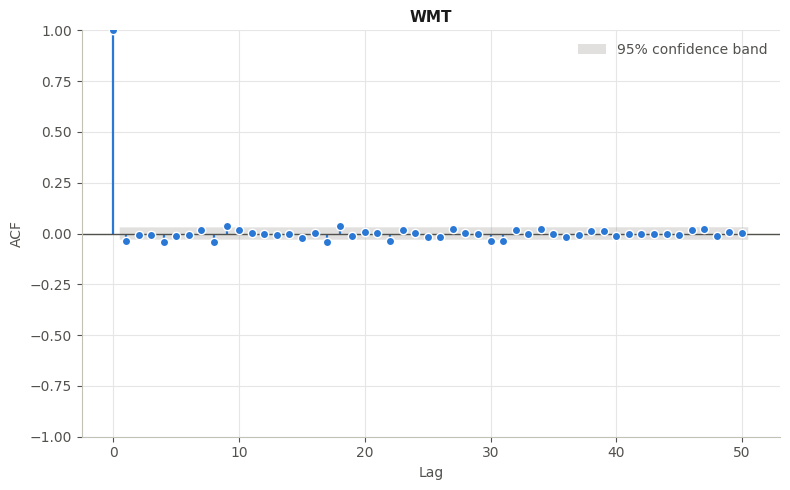

In [18]:
def style_acf_plot(ax):
    """Gives a statsmodels ACF chart (plot_acf) the project colours, after it has been drawn."""
    zero_line = ax.lines[0]                       # horizontal line at ACF = 0
    zero_line.set_color(COLOURS['reference'])
    zero_line.set_linewidth(1)
    dots = ax.lines[1]                            # one dot per lag
    dots.set_markersize(6)
    dots.set_markeredgecolor(COLOURS['background'])
    band = ax.collections[1]                      # shaded 95% confidence band (collections[0] = the vertical bars)
    band.set_facecolor(COLOURS['muted'])
    band.set_alpha(0.25)
    band.set_label('95% confidence band')


# 1. Use the Walmart daily returns
wmt_ret = daily_returns.dropna()

# 2. Create the figure for the ACF chart
fig, ax = plt.subplots(figsize=(8, 5))

# 3. Draw the ACF (50 lags, in the WMT colour)
plot_acf(
    wmt_ret,
    lags=50,
    ax=ax,
    alpha=0.05,            # 95% confidence interval (shaded area/lines)
    color=colour('WMT'),
    vlines_kwargs={'colors': colour('WMT'), 'linewidth': 1.6},
    title="WMT"
)
style_acf_plot(ax)

# Additional visual settings
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Reading:** the autocorrelations of the returns are all very small (between about −0.04 and +0.04): yesterday's return says almost nothing about today's — little serial correlation (fact 1).

## ACF of squared returns: dependence in return magnitude

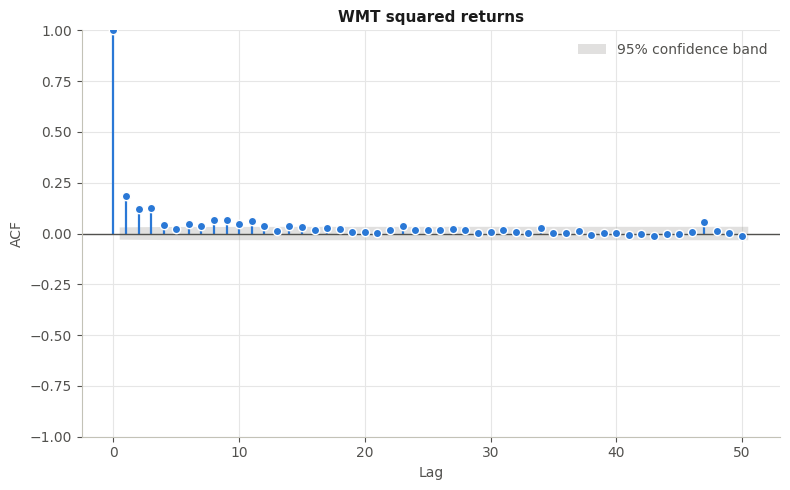

In [19]:
# 1. Get the Walmart daily returns
wmt_ret = daily_returns.dropna()

# 2. Compute the squared log returns (a proxy for volatility)
wmt_ret_sq = wmt_ret ** 2

# 3. Create the figure for the ACF chart
fig, ax = plt.subplots(figsize=(8, 5))

# 4. Draw the ACF of the squared returns (50 lags, in the WMT colour)
plot_acf(
    wmt_ret_sq,
    lags=50,
    ax=ax,
    alpha=0.05,            # 95% confidence interval
    color=colour('WMT'),
    vlines_kwargs={'colors': colour('WMT'), 'linewidth': 1.6},
    title="WMT squared returns"
)
style_acf_plot(ax)   # defined in the ACF cell above

# Visual settings
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Reading:** the autocorrelations of the **squared** returns are positive and decay slowly: large moves tend to follow large moves, whatever their sign — volatility clustering (fact 4).

## WMT vs the market: SPY (investable) and ^GSPC (index)

- **SPY** is an ETF that can be bought; its adjusted price includes dividends, just like WMT's → it is the correct comparison.
- **^GSPC** is the S&P 500 index: it is **not investable** and it is a price index **without dividends**, so it understates the total market return
  (by about 1.5–2 percentage points per year).
- We first select the columns and only then drop the NaN (if we apply `dropna()` to the whole table, the TSLA NaN cut off the first 6 months).

In [20]:
# 1. Load the dataset of daily (log) returns
df_ret = pd.read_csv('data/daily_log_returns.csv', index_col=0, parse_dates=True)

# 2. Select WMT, SPY (investable ETF, with dividends) and ^GSPC (index, without dividends)
#    We first choose the columns and only then drop the NaN
df_sub = df_ret[['WMT', 'SPY', '^GSPC']].dropna()
df_sub.columns = ['WMT', 'SPY (ETF, with dividends)', '^GSPC (index, no dividends)']

# 3. Set the annualisation scale (252 trading days)
annual_scale = 252

# 4. Compute the daily and annualised statistics
mu_log = df_sub.mean()
Sigma_log = df_sub.cov()
sd_log = np.sqrt(np.diag(Sigma_log))

mu_annual = mu_log * annual_scale
Sigma_annual = Sigma_log * annual_scale
sd_annual = sd_log * np.sqrt(annual_scale)

# 5. Table 1: Summary of the estimates
annual_summary = pd.DataFrame({
    'Daily_log_mean': mu_log,
    'Daily_log_SD': sd_log,
    'Annual_log_mean': mu_annual,
    'Annual_log_SD': sd_annual,
    'Annual_geometric_growth': np.expm1(mu_annual)
})

print("Daily and annualised log-return estimates (WMT vs SPY and ^GSPC):")
display(annual_summary.round(5))

# 6. Table 2: Daily covariance matrix
print("\nDaily log-return covariance matrix:")
display(Sigma_log.round(7))

# 7. Table 3: Annualised covariance matrix
print("\nAnnualised log-return covariance matrix:")
display(Sigma_annual.round(5))

Daily and annualised log-return estimates (WMT vs SPY and ^GSPC):


,Daily_log_mean,Daily_log_SD,Annual_log_mean,Annual_log_SD,Annual_geometric_growth
WMT,0.00050,0.01259,0.12682,0.19993,0.13522
"SPY (ETF, with dividends)",0.00052,0.01077,0.13196,0.17092,0.14106
"^GSPC (index, no dividends)",0.00045,0.01084,0.11454,0.17214,0.12136



Daily log-return covariance matrix:


,WMT,"SPY (ETF, with dividends)","^GSPC (index, no dividends)"
WMT,0.000159,0.000057,0.000057
"SPY (ETF, with dividends)",0.000057,0.000116,0.000117
"^GSPC (index, no dividends)",0.000057,0.000117,0.000118



Annualised log-return covariance matrix:


,WMT,"SPY (ETF, with dividends)","^GSPC (index, no dividends)"
WMT,0.03997,0.01427,0.01440
"SPY (ETF, with dividends)",0.01427,0.02921,0.02938
"^GSPC (index, no dividends)",0.01440,0.02938,0.02963


**Reading:** over 2010-2026 WMT grew about as fast as the market (≈ 13.5% a year vs ≈ 14.1% for SPY) with higher volatility (≈ 20% vs ≈ 17%). ^GSPC grew ≈ 2 percentage points a year less than SPY because it excludes dividends — which is why SPY is the benchmark used in the backtest.